# Что первым проверить в интернет-магазине?

У маркетинга девять идей для роста выручки. Сначала выберу, с какой идеи стоит начать. Затем разберу августовский A/B-тест. Особенно меня интересует 19 августа: в этот день у B резко выросла выручка. Хочу понять, стали ли посетители чаще заказывать или всё объясняется одной дорогой покупкой.

В файлах нет описания изменения, которое показывали группе B. Поэтому по результатам эксперимента можно сравнить варианты магазина, а какую именно из девяти гипотез проверяли, мы не знаем.

[Данные](#section-1) · [Приоритеты](#section-2) · [Август по дням](#section-3) · [Редкие заказы](#section-4) · [Проверка различий](#section-5) · [Решение](#section-6)

<a id="section-1"></a>
## 1. Какие данные у нас есть

В `hypothesis.csv` записаны идеи и четыре экспертные оценки. В `orders.csv` одна строка соответствует заказу, в `visitors.csv` — числу посетителей группы за день. Для повторного запуска достаточно положить три CSV рядом с этим ноутбуком и выполнить ячейки сверху вниз.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import dates as mdates
from matplotlib.ticker import FuncFormatter, MaxNLocator, PercentFormatter
from scipy import stats
from IPython.display import display

def read_csv(name, **kwargs):
    for folder in [Path('.'), Path('data'), Path('/datasets')]:
        if (folder / name).is_file():
            return pd.read_csv(folder / name, **kwargs)
    raise FileNotFoundError(f'Положите {name} рядом с ноутбуком.')

hyp = read_csv('hypothesis.csv')
hyp.columns = hyp.columns.str.lower()
orders = read_csv('orders.csv', parse_dates=['date'],
                  dtype={'transactionId': 'string', 'visitorId': 'string'}).rename(
                      columns={'transactionId': 'order_id', 'visitorId': 'buyer_id'})
visitors = read_csv('visitors.csv', parse_dates=['date'])
files = {'Гипотезы': hyp, 'Заказы': orders, 'Посещаемость': visitors}
audit = pd.DataFrame({name: {'Строк': len(df), 'Пропущенных значений': df.isna().sum().sum(),
                             'Полных дублей': df.duplicated().sum()}
                      for name, df in files.items()}).T
display(audit)
display(orders.head(3), visitors.head(3))

groups = ['A', 'B']
assert set(orders['group']) == set(visitors['group']) == set(groups)
assert audit[['Пропущенных значений', 'Полных дублей']].eq(0).all().all()
assert orders['order_id'].is_unique and orders['revenue'].gt(0).all()
assert hyp[['reach', 'impact', 'confidence', 'efforts']].apply(lambda s: s.between(1, 10)).all().all()
calendar = pd.date_range(visitors['date'].min(), visitors['date'].max())
keys = pd.MultiIndex.from_product([calendar, groups], names=['date', 'group'])
assert not visitors.duplicated(['date', 'group']).any()
assert visitors.set_index(['date', 'group']).index.sort_values().equals(keys)
assert visitors['visitors'].gt(0).all() and orders['date'].isin(calendar).all()
print(f'{calendar.min():%d.%m.%Y} — {calendar.max():%d.%m.%Y}, дней наблюдения в каждой группе — {len(calendar)}.')

,Строк,Пропущенных значений,Полных дублей
Гипотезы,9,0,0
Заказы,1197,0,0
Посещаемость,62,0,0


,order_id,buyer_id,date,revenue,group
0,3667963787,3312258926,2019-08-15,1650,B
1,2804400009,3642806036,2019-08-15,730,B
2,2961555356,4069496402,2019-08-15,400,A


,date,group,visitors
0,2019-08-01,A,719
1,2019-08-02,A,619
2,2019-08-03,A,507


01.08.2019 — 31.08.2019, дней наблюдения в каждой группе — 31.


In [2]:
traffic = visitors.groupby('group')['visitors'].sum().reindex(groups)
memberships = orders.groupby('buyer_id')['group'].nunique()
cross_ids = memberships[memberships.gt(1)].index
cross_orders = orders.loc[orders['buyer_id'].isin(cross_ids)]
base = orders.loc[~orders['buyer_id'].isin(cross_ids)].copy()
coverage = pd.concat([traffic.rename('Сумма дневной посещаемости'),
                      orders.groupby('group').size().rename('Заказов в файле'),
                      cross_orders.groupby('group').size().rename('Заказов у пересекающихся ID'),
                      base.groupby('group').size().rename('Заказов после сверки')], axis=1)
display(coverage)
print(f'Заказы в обеих группах есть у {len(cross_ids)} из {len(memberships)} покупателей.')

,Сумма дневной посещаемости,Заказов в файле,Заказов у пересекающихся ID,Заказов после сверки
group,,,,
A,18736,557,89,468
B,18916,640,92,548


Заказы в обеих группах есть у 58 из 1031 покупателей.


За август есть 1 197 заказов. У 58 покупателей встречаются обе буквы, A и B. На них приходится 181 заказ. При построении основных графиков уберу заказы этих покупателей из обеих групп. Останется 468 заказов A и 548 заказов B. В конце покажу и результат по исходному файлу, чтобы было видно, что изменилось после сверки.

В посещаемости нет ID. Известна сумма дневных численностей — 18 736 в A и 18 916 в B. Один человек мог зайти в разные дни, и его визиты после исключения заказов останутся в таблице. Поэтому под **заказами на посетителя** здесь понимаю число заказов, делённое на сумму дневной посещаемости. Для точного расчёта по уникальным участникам за месяц нужен журнал с их ID.

<a id="section-2"></a>
## 2. Скидка на день рождения или форма подписки?

В ICE перемножу влияние и уверенность, а затем разделю на затраты. В RICE добавлю ещё один множитель — охват. Номера 0–8 оставлю такими же, как в исходной таблице. При одинаковых баллах у идей будет общее место.

In [3]:
ideas = hyp.rename_axis('№').copy()
ideas['ICE'] = ideas['impact'] * ideas['confidence'] / ideas['efforts']
ideas['RICE'] = ideas['reach'] * ideas['ICE']
for metric in ['ICE', 'RICE']:
    ideas['Место ' + metric] = ideas[metric].rank(ascending=False, method='min').astype(int)

ice = ideas.sort_values('ICE', ascending=False)
display(ice[['Место ICE', 'hypothesis', 'impact', 'confidence', 'efforts', 'ICE']]
        .rename(columns={'hypothesis': 'Гипотеза'}).style.format({'ICE': '{:.2f}'}))

,Место ICE,Гипотеза,impact,confidence,efforts,ICE
№,,,,,,
8,1,"Запустить акцию, дающую скидку на товар в день рождения",9,9,5,16.20
0,2,"Добавить два новых канала привлечения трафика, что позволит привлекать на 30% больше пользователей",10,8,6,13.33
7,3,"Добавить форму подписки на все основные страницы, чтобы собрать базу клиентов для email-рассылок",7,8,5,11.20
6,4,"Показать на главной странице баннеры с актуальными акциями и распродажами, чтобы увеличить конверсию",3,8,3,8.00
2,5,"Добавить блоки рекомендаций товаров на сайт интернет магазина, чтобы повысить конверсию и средний чек заказа",3,7,3,7.00
1,6,"Запустить собственную службу доставки, что сократит срок доставки заказов",5,4,10,2.00
5,7,"Добавить страницу отзывов клиентов о магазине, что позволит увеличить количество заказов",2,2,3,1.33
3,8,"Изменить структура категорий, что увеличит конверсию, т.к. пользователи быстрее найдут нужный товар",3,3,8,1.12
4,9,"Изменить цвет фона главной страницы, чтобы увеличить вовлеченность пользователей",1,1,1,1.00


Первой по ICE идёт **скидка на день рождения** (№ 8). У неё по 9 баллов за влияние и уверенность при затратах 5. Получается 16,2 балла. Далее идут два новых канала привлечения (13,33) и форма подписки (11,2).

In [4]:
rice = ideas.sort_values(['RICE', 'ICE'], ascending=False)
display(rice[['Место RICE', 'hypothesis', 'reach', 'ICE', 'RICE', 'Место ICE']]
        .rename(columns={'hypothesis': 'Гипотеза', 'reach': 'Охват'})
        .style.format({'ICE': '{:.2f}', 'RICE': '{:.2f}'}))

,Место RICE,Гипотеза,Охват,ICE,RICE,Место ICE
№,,,,,,
7,1,"Добавить форму подписки на все основные страницы, чтобы собрать базу клиентов для email-рассылок",10,11.20,112.00,3
2,2,"Добавить блоки рекомендаций товаров на сайт интернет магазина, чтобы повысить конверсию и средний чек заказа",8,7.00,56.00,5
0,3,"Добавить два новых канала привлечения трафика, что позволит привлекать на 30% больше пользователей",3,13.33,40.00,2
6,3,"Показать на главной странице баннеры с актуальными акциями и распродажами, чтобы увеличить конверсию",5,8.00,40.00,4
8,5,"Запустить акцию, дающую скидку на товар в день рождения",1,16.20,16.20,1
3,6,"Изменить структура категорий, что увеличит конверсию, т.к. пользователи быстрее найдут нужный товар",8,1.12,9.00,8
1,7,"Запустить собственную службу доставки, что сократит срок доставки заказов",2,2.00,4.00,6
5,7,"Добавить страницу отзывов клиентов о магазине, что позволит увеличить количество заказов",3,1.33,4.00,7
4,9,"Изменить цвет фона главной страницы, чтобы увеличить вовлеченность пользователей",3,1.00,3.00,9


По RICE я бы первым взял **форму подписки на основных страницах** (№ 7). Её охват оценили в 10 баллов, и оценка поднялась до 112. Скидка на день рождения касается узкой аудитории. При охвате 1 её балл остался 16,2, а место изменилось с первого на пятое.

Интересен и второй результат. Блок рекомендаций (№ 2) поднялся с пятого места на второе благодаря охвату 8. Новые каналы и баннеры с акциями делят третье место по RICE — у обеих идей 40 баллов. Для подписки я бы в будущем следил и за заказами из рассылки: рост числа адресов сам по себе ещё не отвечает на вопрос о выручке.

<a id="section-3"></a>
## 3. Что происходило в августе

Для каждого дня сначала сложу заказы, выручку и посетителей отдельно в A и B. Из накопленных сумм получу средний чек и заказы на посетителя. Так дни с разным трафиком получат правильный вес.

In [5]:
daily_orders = base.groupby(['date', 'group']).agg(revenue=('revenue', 'sum'), orders=('order_id', 'size'))
daily = visitors.set_index(['date', 'group']).sort_index().join(daily_orders).fillna(0)
cum = daily.groupby(level='group').cumsum()
cum['ticket'] = cum['revenue'] / cum['orders'].replace(0, np.nan)
cum['frequency'] = cum['orders'] / cum['visitors']
display(cum.loc[calendar[-1]].rename(columns={'visitors': 'Посещаемость', 'revenue': 'Выручка',
        'orders': 'Заказы', 'ticket': 'Средний чек', 'frequency': 'Заказов на посетителя'})
        .style.format({'Средний чек': '{:,.2f}', 'Заказов на посетителя': '{:.5f}'}))

,Посещаемость,Выручка,Заказы,Средний чек,Заказов на посетителя
group,,,,,
A,18736,3364656,468,"7,189.44",0.02498
B,18916,5068972,548,"9,249.95",0.02897


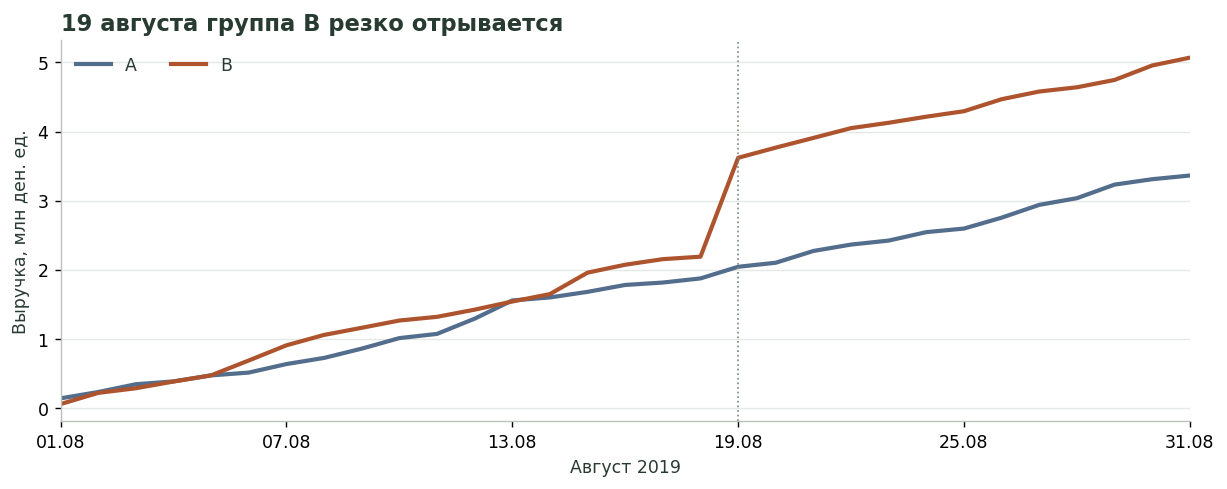

In [6]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'figure.dpi': 125,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlesize': 13,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b8c3bb',
                     'axes.axisbelow': True, 'legend.frameon': False, 'text.color': '#283b31',
                     'axes.labelcolor': '#283b31', 'figure.facecolor': 'white'})
colors = {'A': '#536d8c', 'B': '#ad542e'}
green = '#26715c'
def line_chart(ax, metric, title, ylabel, relative=False, scale=1):
    wide = cum[metric].unstack('group')
    if relative:
        ax.plot(wide.index, wide['B'].div(wide['A']).sub(1) * 100, lw=2.4, color=green)
        ax.axhline(0, lw=1, ls='--', color='#637166')
        ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    else:
        for group in groups:
            ax.plot(wide.index, wide[group] * scale, lw=2.4, label=group, color=colors[group])
        ax.legend(loc='best', ncol=2)
    ax.set(title=title, ylabel=ylabel, xlabel='Август 2019')
    ax.set_xlim(calendar[0], calendar[-1])
    ax.set_xticks(calendar[::6])
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
    ax.grid(axis='y', color='#e3e9e4')

fig, ax = plt.subplots(figsize=(9.7, 3.8), layout='constrained')
line_chart(ax, 'revenue', '19 августа группа B резко отрывается', 'Выручка, млн ден. ед.', scale=1e-6)
ax.axvline(pd.Timestamp('2019-08-19'), color='#828d82', ls=':', lw=1)
plt.show()

К концу месяца у B накопилось 5,07 млн выручки, у A — 3,36 млн. Запомним 19 августа. Чтобы понять, откуда взялась ступенька на графике, посмотрим отдельно этот день.

In [7]:
peak = base.loc[base['revenue'].idxmax()]
peak_day = daily.loc[peak['date'], ['orders', 'revenue']]
display(peak_day.rename(columns={'orders': 'Заказов в этот день', 'revenue': 'Выручка за день'}))
print(f"Крупнейший заказ: {peak['revenue']:,.0f}. "
      f"Доля в выручке своей группы за день: {peak['revenue'] / peak_day.loc[peak['group'], 'revenue']:.1%}.")

,Заказов в этот день,Выручка за день
group,,
A,21,168193
B,21,1429920


Крупнейший заказ: 1,294,500. Доля в выручке своей группы за день: 90.5%.


В тот день **у обеих групп по 21 заказу**, но у B есть покупка на **1 294 500**. Она дала 90,5% дневной выручки B. Теперь понятно, почему на графике появился такой отрыв.

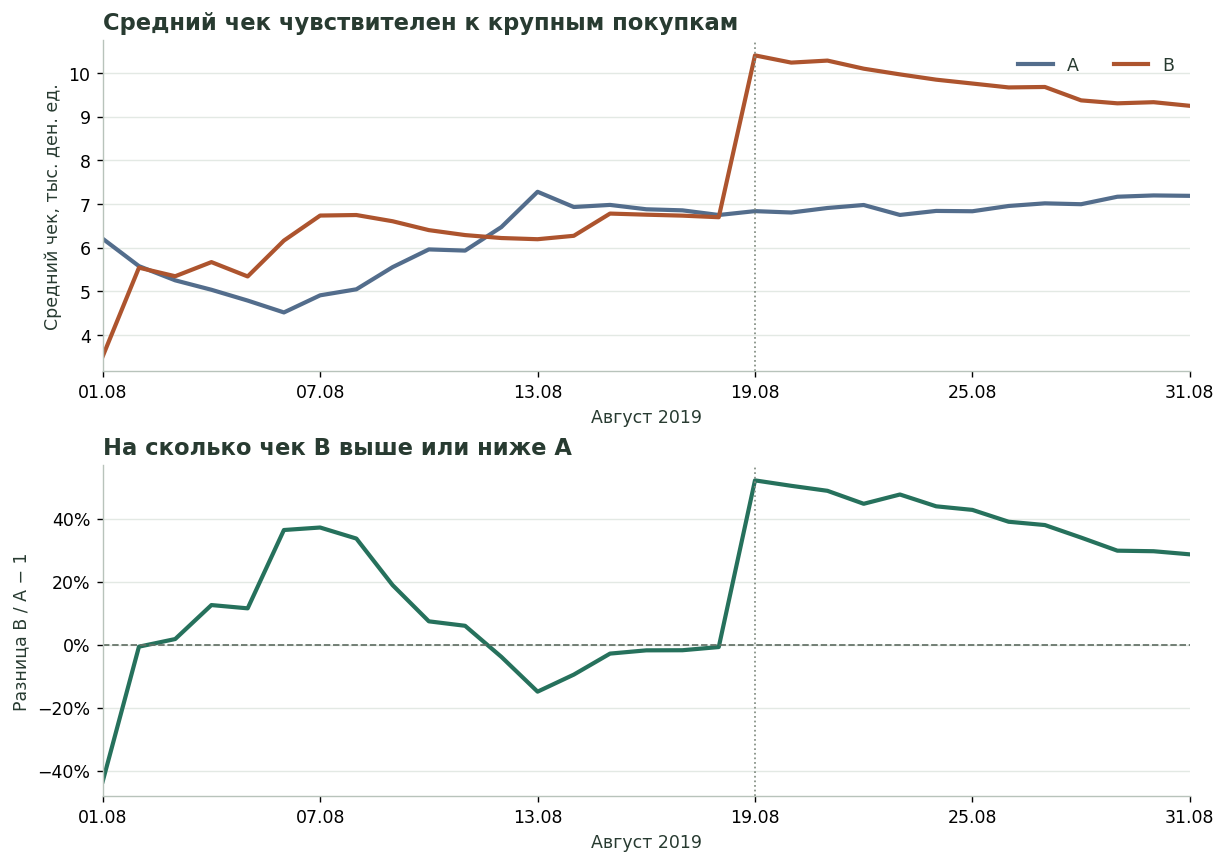

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(9.7, 6.8), layout='constrained')
line_chart(axes[0], 'ticket', 'Средний чек чувствителен к крупным покупкам', 'Средний чек, тыс. ден. ед.', scale=0.001)
line_chart(axes[1], 'ticket', 'На сколько чек B выше или ниже A', 'Разница B / A − 1', relative=True)
for ax in axes:
    ax.axvline(peak['date'], lw=1, ls=':', color='#828d82')
plt.show()

До 19 августа преимущество по среднему чеку переходит от одной группы к другой. После дорогой покупки разница резко уходит вверх, а затем постепенно сокращается. На последнюю дату чек B всё ещё выше на **28,7%**. По одному этому числу я бы не делал вывод, что покупатели B в целом стали тратить больше.

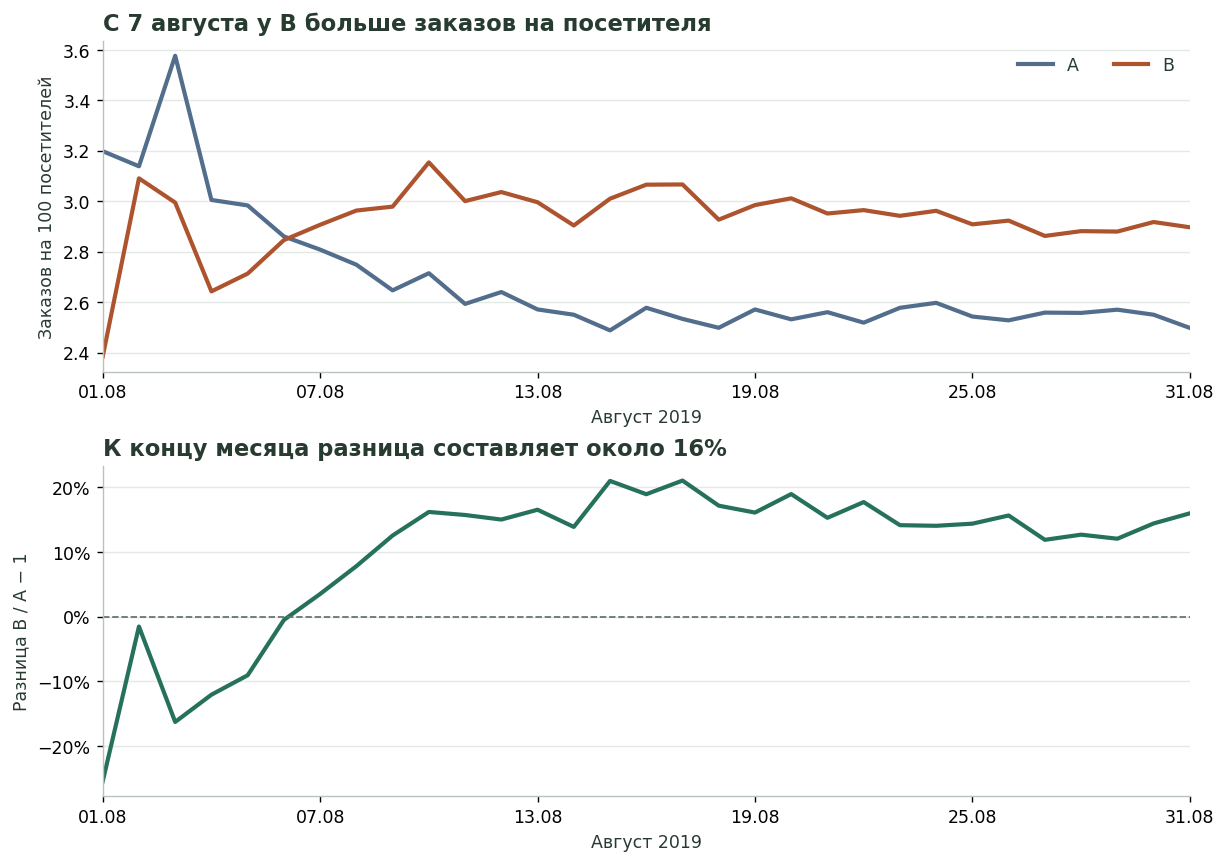

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(9.7, 6.8), layout='constrained')
line_chart(axes[0], 'frequency', 'С 7 августа у B больше заказов на посетителя', 'Заказов на 100 посетителей', scale=100)
line_chart(axes[1], 'frequency', 'К концу месяца разница составляет около 16%', 'Разница B / A − 1', relative=True)
plt.show()

С частотой заказов история другая. B выходит вперёд **7 августа**, почти за две недели до крупной покупки, и дальше остаётся выше A. На конец месяца получается **2,90 против 2,50 заказа на 100 посетителей**. Разница составляет около **0,40 заказа на 100**, или **+16,0%** относительно A. Повторные заказы одного покупателя здесь учитываются.

Каждая следующая точка включает предыдущие дни. Поэтому статистическую проверку проведу один раз по итогам августа.

<a id="section-4"></a>
## 4. Какие заказы заметно меняют результат

Посмотрим на обе группы вместе. Для количества заказов беру покупателей, у которых есть хотя бы один заказ и однозначно известна группа. Для стоимости использую все их заказы. Пороги будут одинаковыми для A и B.

,Заказов у покупателя,Стоимость заказа
95-й перцентиль,1.0,26785.0
99-й перцентиль,2.0,53904.0


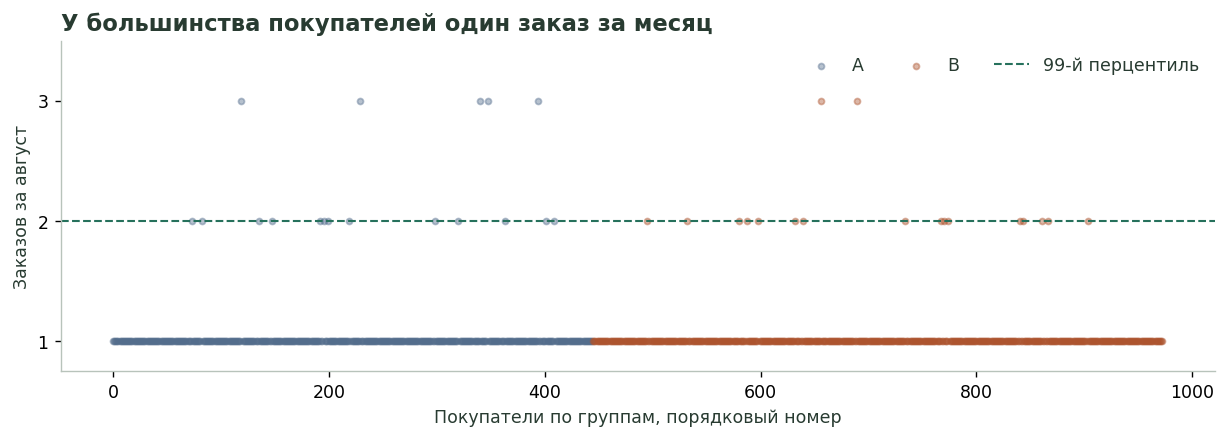

In [10]:
per_buyer = base.groupby(['group', 'buyer_id']).size().rename('orders').reset_index()
quantiles = pd.DataFrame({'Заказов у покупателя': per_buyer['orders'].quantile([.95, .99]),
                          'Стоимость заказа': base['revenue'].quantile([.95, .99])})
display(quantiles.rename(index={.95: '95-й перцентиль', .99: '99-й перцентиль'}))
order_limit = quantiles.loc[.99, 'Заказов у покупателя']
price_limit = quantiles.loc[.99, 'Стоимость заказа']

fig, ax = plt.subplots(figsize=(9.7, 3.4), layout='constrained')
for group, frame in per_buyer.groupby('group'):
    ax.scatter(frame.index, frame['orders'], color=colors[group], s=12, alpha=.42, label=group)
ax.axhline(order_limit, ls='--', color=green, lw=1.2, label='99-й перцентиль')
ax.set(title='У большинства покупателей один заказ за месяц', xlabel='Покупатели по группам, порядковый номер',
       ylabel='Заказов за август', yticks=[1, 2, 3], ylim=(0.75, 3.5))
ax.legend(ncol=3)
plt.show()

У 937 из 973 покупателей всего один заказ. 95-й перцентиль равен 1, 99-й — 2. Для проверки устойчивости отмечу покупателей с **тремя и более заказами**. Если взять границу по 95-му перцентилю, из расчёта исчезнут вообще все повторные покупки.

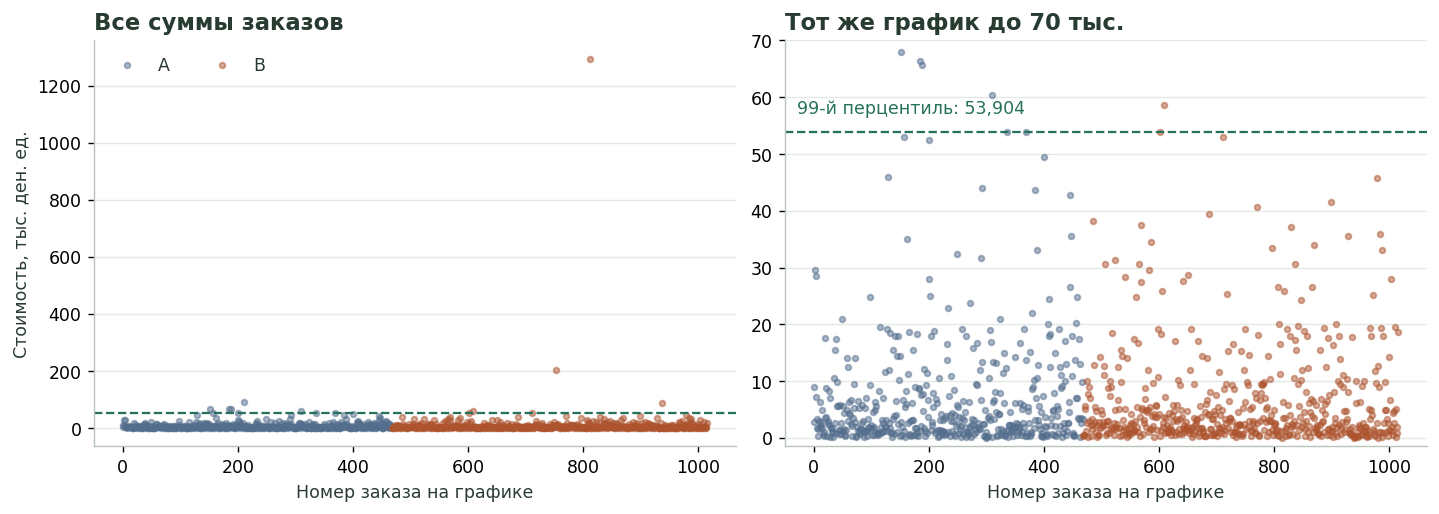

In [11]:
plot_orders = base.sort_values(['group', 'date', 'order_id']).reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4), layout='constrained')
for ax in axes:
    for group, frame in plot_orders.groupby('group'):
        ax.scatter(frame.index, frame['revenue'], color=colors[group], alpha=.5, s=11, label=group)
    ax.axhline(price_limit, color=green, ls='--', lw=1.3)
    ax.set_xlabel('Номер заказа на графике')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1000:g}'))
    ax.grid(axis='y', color='#e3e9e4')
axes[0].set(title='Все суммы заказов', ylabel='Стоимость, тыс. ден. ед.')
axes[0].legend(ncol=2)
axes[1].set(title='Тот же график до 70 тыс.', ylim=(-1500, 70000))
axes[1].text(.02, .82, f'99-й перцентиль: {price_limit:,.0f}', color=green, transform=axes[1].transAxes)
plt.show()

Самый дорогой заказ — 1 294 500, следующий за ним — 202 740. Поэтому справа я увеличил участок до 70 тысяч. Здесь видно, где проходит граница очистки. 95% заказов стоят до **26 785**, 99% — до **53 904** включительно. Для очистки выберу строгое превышение 53 904. Сам факт крупной покупки не делает её ошибкой — она остаётся в исходных результатах.

In [12]:
frequent = set(per_buyer.loc[per_buyer['orders'].gt(order_limit), 'buyer_id'])
expensive = set(base.loc[base['revenue'].gt(price_limit), 'buyer_id'])
flagged = frequent | expensive
removed = base.loc[base['buyer_id'].isin(flagged)]
clean = base.loc[~base['buyer_id'].isin(flagged)].copy()
excluded_buyers = removed.groupby('group')['buyer_id'].nunique().reindex(groups, fill_value=0)
display(removed.groupby('group').agg(Покупателей=('buyer_id', 'nunique'), Заказов=('order_id', 'size'),
                                    Выручка=('revenue', 'sum')))
print(f'Выше порога по частоте: {len(frequent)}, по сумме: {len(expensive)}, всего покупателей: {len(flagged)}.')

,Покупателей,Заказов,Выручка
group,,,
A,10,20,458469
B,6,10,1691803


Выше порога по частоте: 7, по сумме: 9, всего покупателей: 16.


Под одно из условий попали **16 покупателей**. Для очищенного среза исключу все их заказы. Так один пользователь целиком попадает в выборку или целиком выходит из неё. Исходный файл и результаты до очистки остаются доступными для сравнения.

<a id="section-5"></a>
## 5. Есть ли различие между A и B?

Основной показатель для решения — **заказы на посетителя**. Средний чек покажет, как различаются суммы покупок. Для каждой метрики нулевая гипотеза — равенство её средних в A и B, альтернативная — различие в любую сторону. Уровень значимости беру **0,05** для основной метрики. Очистку использую как проверку чувствительности того же результата.

Для заказов на посетителя применю двусторонний **тест Уэлча**. Покупатель представлен своим количеством заказов, а оставшиеся места до размера группы заполнены нулями. Это приближение требует трактовать дневные посещения как независимых участников. В очищенном срезе вычту по одной записи на каждого из 10 исключённых покупателей A и 6 покупателей B, сохранив прежнее число нулей. Более точное число их посещений за месяц по этим файлам недоступно.

Для среднего чека посчитаю разность средних по заказам. При оценке её стандартной ошибки объединю заказы одного покупателя в один кластер: повторные покупки могут быть связаны. Использую нормальное приближение для разности двух отношений «выручка / заказы». При одном исключительно дорогом заказе точность такой оценки ограничена.

Также приведу двусторонний **критерий Манна — Уитни**, как в исходном проекте. Он сравнивает ранги наблюдений. Его p-value помогает увидеть, насколько результат зависит от метода. Разницу именно в арифметических средних оцениваю отдельно.

In [13]:
def frequency_samples(data, denominators):
    counts = data.groupby(['group', 'buyer_id']).size()
    samples = []
    for group in groups:
        buyers = counts.loc[group].to_numpy()
        zero_count = int(denominators[group]) - len(buyers)
        samples.append(np.r_[buyers, np.zeros(zero_count, dtype=int)])
    return samples

def ticket_stats(frame):
    # Линеаризация отношения суммарной выручки к суммарному числу заказов.
    by_buyer = frame.groupby('buyer_id').agg(total=('revenue', 'sum'), count=('order_id', 'size'))
    mean = by_buyer['total'].sum() / by_buyer['count'].sum()
    residual = by_buyer['total'] - mean * by_buyer['count']
    variance = len(by_buyer) * residual.var(ddof=1) / by_buyer['count'].sum() ** 2
    return mean, variance

def compare(data, denominators, name):
    freq_a, freq_b = frequency_samples(data, denominators)
    check_a, check_b = [data.loc[data['group'].eq(g)] for g in groups]
    a, var_a = ticket_stats(check_a)
    b, var_b = ticket_stats(check_b)
    p_ticket = 2 * stats.norm.sf(abs(b - a) / np.sqrt(var_a + var_b))
    rows = []
    for label, x, y, p_mean, scale in [
        ('Заказов на 100 посетителей', freq_a, freq_b, stats.ttest_ind(freq_a, freq_b, equal_var=False).pvalue, 100),
        ('Средний чек', check_a['revenue'], check_b['revenue'], p_ticket, 1),
    ]:
        rank_p = stats.mannwhitneyu(x, y, alternative='two-sided', method='asymptotic').pvalue
        rows.append({'Данные': name, 'Метрика': label, 'A': x.mean() * scale, 'B': y.mean() * scale,
                     'B к A': y.mean() / x.mean() - 1, 'p средних': p_mean, 'p рангов': rank_p})
    return rows

rows = compare(orders, traffic, 'Весь исходный файл')
rows += compare(base, traffic, 'После сверки групп, до очистки')
rows += compare(clean, traffic - excluded_buyers, 'После сверки и очистки')
results = pd.DataFrame(rows).set_index(['Метрика', 'Данные'])
formats = {'A': '{:,.3f}', 'B': '{:,.3f}', 'B к A': '{:+.2%}', 'p средних': '{:.4f}', 'p рангов': '{:.4f}'}
display(results.loc['Заказов на 100 посетителей'].style.format(formats))

,A,B,B к A,p средних,p рангов
Данные,,,,,
Весь исходный файл,2.973,3.383,+13.81%,0.0479,0.0168
"После сверки групп, до очистки",2.498,2.897,+15.98%,0.0227,0.0110
После сверки и очистки,2.392,2.845,+18.92%,0.0076,0.0070


По всем зарегистрированным заказам преимущество B составляет **13,8%**. В этой строке есть одни и те же покупатели в разных группах, поэтому p-value здесь только ориентир. После сверки групп, **до удаления редких заказов**, получаем **+16,0%**, p Уэлча **0,0227**, p Манна — Уитни **0,0110**.

После очистки преимущество составляет **+18,9%**, p Уэлча **0,0076**, ранговый p **0,0070**. При принятых допущениях отвергаю гипотезу о равной частоте заказов. Направление результата сохраняется во всех трёх срезах. Сам рост процента после очистки ещё не означает, что эффект в реальном магазине будет именно 18,9%.

In [14]:
display(results.loc['Средний чек'].style.format(formats))
without_largest = base.drop(index=peak.name).groupby('group')['revenue'].mean()
print(f"Если убрать только заказ 19 августа на {peak['revenue']:,.0f}, "
      f"разница чеков B к A составит {without_largest['B'] / without_largest['A'] - 1:+.2%}.")

# Насколько вывод о частоте зависит от приближённой корректировки посещаемости?
fixed = clean.groupby('group').size() / traffic
print(f"После очистки с неизменным знаменателем разница частот составит {fixed['B'] / fixed['A'] - 1:+.2%}.")

,A,B,B к A,p средних,p рангов
Данные,,,,,
Весь исходный файл,"7,333.578","9,230.875",+25.87%,0.3752,0.7293
"После сверки групп, до очистки","7,189.436","9,249.949",+28.66%,0.4040,0.8295
После сверки и очистки,"6,487.025","6,277.266",-3.23%,0.7120,0.7877


Если убрать только заказ 19 августа на 1,294,500, разница чеков B к A составит -4.02%.
После очистки с неизменным знаменателем разница частот составит +18.95%.


По исходному файлу средний чек B больше на **25,9%**, после сверки групп — на **28,7%**. Но если убрать только крупнейший заказ 19 августа, средний чек B уже на 4,0% ниже чека A. После полной очистки получаем **6 487 в A и 6 277 в B**, разница **−3,2%**. После сверки групп p для разницы средних чеков равен 0,4040 до очистки и 0,7120 после неё. В ранговой проверке вывод тот же.

Оснований считать, что B увеличивает средний чек, я не вижу. Размер разницы слишком чувствителен к отдельным заказам, чтобы говорить и о гарантированном равенстве чеков.

<a id="section-6"></a>
## 6. Моё решение

**Выбираю вариант 1. Остановить тест и зафиксировать преимущество B по числу заказов на посетителя.** После сверки групп в августе на каждые 100 посетителей пришлось 2,90 заказа в B и 2,50 в A. Разрыв появился ещё до крупной покупки 19 августа. После удаления редких заказов он сохранился, и обе статистические проверки дали тот же вывод.

Для среднего чека победителя зафиксировать нельзя. Один заказ поднял месячную среднюю B настолько, что его исключение меняет знак разницы. По этим данным я бы не закладывал рост среднего чека в прогноз выручки.

Перед распространением B на весь трафик я бы проверил, почему 58 покупателей оказались в обеих группах, и запросил выгрузку назначений с ID посетителей. Тогда можно проверить абсолютную величину эффекта по уникальным участникам. Продление этого же теста само по себе вопрос с разметкой не решает.

Для **следующего** эксперимента я бы предложил форму подписки. Она первой выходит по RICE за счёт охвата. В новом тесте заранее задал бы метрику заказов и срок наблюдения, чтобы учесть время от подписки до покупки.